# Universidad Diego Portales
## Facultad de Ingeniería y Ciencias
### Curso: Inteligencia Artificial
**Tarea N° 2 - Aprendizaje Supervisado y No Supervisado**

**Autores:** Jeremías Olivares, Benjamín Arango

---
## Ítem 1: Regresión Lineal y Logística

Para esta sección, hemos seleccionado el dataset **"Work Productivity"**, el cual cuenta con 30.000 registros y 17 características.

Se han definido las siguientes variables objetivo:
* **Variable Continua ($Y_1$):** `Productivity_Score` (Puntaje de productividad). Se predecirá utilizando **Regresión Lineal**.
* **Variable Discreta Binaria ($Y_2$):** `Burnout_Risk` (Riesgo de desgaste profesional). Se predecirá utilizando **Regresión Logística**.

### 1.1 Carga, Preprocesamiento y Partición de Datos
Transformaremos las variables categóricas ordinales a numéricas y dividiremos el dataset estrictamente en 70% Entrenamiento, 15% Validación y 15% Prueba.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

# Cargar el dataset
df = pd.read_csv("Work Productivity.csv")

# Transformar variables categóricas a numéricas
df['Burnout_Risk'] = df['Burnout_Risk'].map({'No': 0, 'Yes': 1})
df['Stress_Level'] = df['Stress_Level'].map({'Low': 1, 'Medium': 2, 'High': 3})
df['Company_Size'] = df['Company_Size'].map({'Small': 1, 'Medium': 2, 'Large': 3})

# Definir variables objetivo y las 10 predictoras iniciales
target_y1 = 'Productivity_Score'  
target_y2 = 'Burnout_Risk'        

features_x = [
    'Age', 'Experience_Years', 'Work_Hours_Per_Day', 'Meetings_Per_Day', 
    'Internet_Speed_Mbps', 'Sleep_Hours', 'Exercise_Hours_Per_Week', 
    'Screen_Time_Hours', 'Stress_Level', 'Company_Size'
]

# Limpiar datos nulos
df_model = df[features_x + [target_y1, target_y2]].dropna()

X = df_model[features_x]
y1 = df_model[target_y1]
y2 = df_model[target_y2]

# Partición 70% Train / 30% Temporal
X_train, X_temp, y1_train, y1_temp, y2_train, y2_temp = train_test_split(
    X, y1, y2, test_size=0.30, random_state=42
)

# Partición del 30% Temporal en 15% Validation / 15% Test
X_val, X_test, y1_val, y1_test, y2_val, y2_test = train_test_split(
    X_temp, y1_temp, y2_temp, test_size=0.50, random_state=42
)

print(f"Dimensiones finales tras partición:")
print(f"Train: {len(X_train)} filas | Validation: {len(X_val)} filas | Test: {len(X_test)} filas")

Dimensiones finales tras partición:
Train: 15732 filas | Validation: 3371 filas | Test: 3372 filas


### 1.2 Selección de Variables (Feature Selection)
La selección de características se justifica empleando exclusivamente el conjunto de entrenamiento. Calculamos la correlación lineal de Pearson (valor absoluto) de las 10 variables predictoras respecto a $Y_1$ e $Y_2$ en `X_train`.
    

In [2]:
# Calcular correlaciones absolutas solo en los datos de entrenamiento
corr_y1 = X_train.corrwith(y1_train).abs().sort_values(ascending=False)
corr_y2 = X_train.corrwith(y2_train).abs().sort_values(ascending=False)

print("--- Top Predictoras para Y1 (Productividad) ---")
print(corr_y1.head(5))

print("\n--- Top Predictoras para Y2 (Riesgo de Burnout) ---")
print(corr_y2.head(5))

# Definición unificada de subconjuntos basados en los resultados
vars_10 = features_x
vars_5 = ['Sleep_Hours', 'Work_Hours_Per_Day', 'Exercise_Hours_Per_Week', 'Internet_Speed_Mbps', 'Meetings_Per_Day']
vars_3 = ['Sleep_Hours', 'Work_Hours_Per_Day', 'Exercise_Hours_Per_Week']

--- Top Predictoras para Y1 (Productividad) ---
Sleep_Hours                0.629253
Work_Hours_Per_Day         0.470003
Exercise_Hours_Per_Week    0.369818
Internet_Speed_Mbps        0.288948
Meetings_Per_Day           0.248221
dtype: float64

--- Top Predictoras para Y2 (Riesgo de Burnout) ---
Sleep_Hours                0.446083
Work_Hours_Per_Day         0.337266
Exercise_Hours_Per_Week    0.265547
Internet_Speed_Mbps        0.204131
Meetings_Per_Day           0.174212
dtype: float64


### 1.3 Entrenamiento y Evaluación: Regresión Lineal (Y1)
Entrenaremos tres versiones del modelo (10, 5 y 3 variables) para predecir la Productividad Continua. Compararemos el **Error Cuadrático Medio (MSE)** y el **Coeficiente de Determinación ($R^2$)** en los conjuntos de Entrenamiento y Validación. Finalmente, los dos mejores modelos se evaluarán en el conjunto de Prueba.

In [3]:
def evaluar_lineal(variables, nombre):
    modelo = LinearRegression()
    modelo.fit(X_train[variables], y1_train)
    p_train = modelo.predict(X_train[variables])
    p_val = modelo.predict(X_val[variables])
    
    mse_val = mean_squared_error(y1_val, p_val)
    r2_val = r2_score(y1_val, p_val)
    
    print(f"--- {nombre} ---")
    print(f"Train -> MSE: {mean_squared_error(y1_train, p_train):.2f} | R2: {r2_score(y1_train, p_train):.4f}")
    print(f"Val   -> MSE: {mse_val:.2f} | R2: {r2_val:.4f}\n")
    return modelo, r2_val, variables

print("RESULTADOS REGRESIÓN LINEAL (Validación)\n" + "="*40)
m10 = evaluar_lineal(vars_10, "10 Variables")
m5 = evaluar_lineal(vars_5, "5 Variables")
m3 = evaluar_lineal(vars_3, "3 Variables")

# Selección automática de los 2 mejores según R2 en validación
modelos_lineales = [m10, m5, m3]
modelos_lineales.sort(key=lambda x: x[1], reverse=True)
top_2_lineales = modelos_lineales[:2]

print("EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST) - TOP 2 AUTOMÁTICO\n" + "="*55)
for modelo, r2_val, variables in top_2_lineales:
    p_test = modelo.predict(X_test[variables])
    print(f"Modelo {len(variables)} Vars (Test) -> MSE: {mean_squared_error(y1_test, p_test):.2f} | R2: {r2_score(y1_test, p_test):.4f}")

RESULTADOS REGRESIÓN LINEAL (Validación)
--- 10 Variables ---
Train -> MSE: 22.04 | R2: 0.9251
Val   -> MSE: 22.83 | R2: 0.9229

--- 5 Variables ---
Train -> MSE: 34.56 | R2: 0.8826
Val   -> MSE: 35.32 | R2: 0.8807

--- 3 Variables ---
Train -> MSE: 75.55 | R2: 0.7433
Val   -> MSE: 76.93 | R2: 0.7401

EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST) - TOP 2 AUTOMÁTICO
Modelo 10 Vars (Test) -> MSE: 23.23 | R2: 0.9219
Modelo 5 Vars (Test) -> MSE: 35.91 | R2: 0.8793


### 1.4 Entrenamiento y Evaluación: Regresión Logística (Y2)
Para el problema de clasificación binaria (Riesgo de Burnout), es necesario escalar los datos. Evaluaremos el desempeño utilizando **Accuracy** y **F1-Score**. Al igual que en el caso anterior, los dos mejores modelos de validación se probarán en el conjunto Test.

In [4]:
# Escalado de datos
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_val_s = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

def evaluar_logistica(variables, nombre):
    modelo = LogisticRegression(max_iter=1000, random_state=42)
    modelo.fit(X_train_s[variables], y2_train)
    p_train = modelo.predict(X_train_s[variables])
    p_val = modelo.predict(X_val_s[variables])
    
    acc_val = accuracy_score(y2_val, p_val)
    
    print(f"--- {nombre} ---")
    print(f"Train -> Accuracy: {accuracy_score(y2_train, p_train):.4f} | F1: {f1_score(y2_train, p_train, zero_division=0):.4f}")
    print(f"Val   -> Accuracy: {acc_val:.4f} | F1: {f1_score(y2_val, p_val, zero_division=0):.4f}\n")
    return modelo, acc_val, variables

print("RESULTADOS REGRESIÓN LOGÍSTICA (Validación)\n" + "="*45)
m10_log = evaluar_logistica(vars_10, "10 Variables")
m5_log = evaluar_logistica(vars_5, "5 Variables")
m3_log = evaluar_logistica(vars_3, "3 Variables")

# Selección automática de los 2 mejores según Accuracy en validación
modelos_logisticos = [m10_log, m5_log, m3_log]
modelos_logisticos.sort(key=lambda x: x[1], reverse=True)
top_2_logisticos = modelos_logisticos[:2]

print("EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST) - TOP 2 AUTOMÁTICO\n" + "="*55)
for modelo, acc_val, variables in top_2_logisticos:
    p_test = modelo.predict(X_test_s[variables])
    print(f"Modelo {len(variables)} Vars (Test) -> Accuracy: {accuracy_score(y2_test, p_test):.4f} | F1: {f1_score(y2_test, p_test, zero_division=0):.4f}")

RESULTADOS REGRESIÓN LOGÍSTICA (Validación)
--- 10 Variables ---
Train -> Accuracy: 0.9457 | F1: 0.8605
Val   -> Accuracy: 0.9454 | F1: 0.8614

--- 5 Variables ---
Train -> Accuracy: 0.9288 | F1: 0.8153
Val   -> Accuracy: 0.9288 | F1: 0.8168

--- 3 Variables ---
Train -> Accuracy: 0.8884 | F1: 0.6969
Val   -> Accuracy: 0.8834 | F1: 0.6838

EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST) - TOP 2 AUTOMÁTICO
Modelo 10 Vars (Test) -> Accuracy: 0.9389 | F1: 0.8470
Modelo 5 Vars (Test) -> Accuracy: 0.9232 | F1: 0.8042


### 1.5 Análisis de Generalización y Desempeño

Al observar el comportamiento de los modelos, concluimos lo siguiente respecto a la cantidad de variables y su capacidad de generalización:

1. **Impacto de la dimensionalidad:** El modelo con 10 variables posee el mejor desempeño absoluto tanto en la Regresión Lineal como en la Logística. Sin embargo, el modelo de 5 variables logra retener la mayor parte de la capacidad predictiva, demostrando que las horas de sueño, horas de trabajo y horas de ejercicio concentran la varianza fundamental del dataset.
2. **Underfitting (Subajuste):** El modelo de 3 variables sufre de un ligero underfitting. Al eliminar demasiada información predictiva, su coeficiente de determinación ($R^2$) y su F1-Score caen significativamente en comparación con el modelo de 10 variables, limitando su capacidad para modelar la complejidad del fenómeno.
3. **Overfitting (Sobreajuste):** No se evidencia una situación grave de overfitting en los modelos de 10 variables, ya que el rendimiento en el conjunto de Entrenamiento se mantiene consistente al ser evaluado en los conjuntos de Validación y Prueba. Las métricas no sufren una degradación abrupta frente a datos no observados.

## Ítem 2: Aprendizaje Supervisado vs. Semisupervisado (Clasificación Multiclase)

### Marco Conceptual y Diseño Experimental

* **Aprendizaje Supervisado:** El modelo aprende exclusivamente a partir de muestras con etiqueta conocida. Con conjuntos de datos reducidos (10% o 30% del conjunto de entrenamiento), la varianza del estimador es elevada.
* **Aprendizaje Semisupervisado (*Cluster-and-Label*):** Se agrupan todas las muestras del entrenamiento sin utilizar etiquetas y se propaga la clase mayoritaria de cada clúster a los elementos no etiquetados. Esto se fundamenta en la **hipótesis de clúster** (puntos geográficamente cercanos comparten etiqueta).
* **Diseño Experimental:**
  1. Partición estricta 80% entrenamiento / 20% prueba (estratificada por clase). El conjunto de test se aísla por completo.
  2. Simulación de escenarios donde el entrenamiento cuenta únicamente con un **10%** y un **30%** de etiquetas reales (anidadas).
  3. Comparación de modelos supervisados base (**Regresión Logística** y **SVM RBF**) frente a esquemas semisupervisados utilizando **K-Means** y **DBSCAN** para la generación de pseudoetiquetas.
  4. Validación cruzada estratificada sobre las etiquetas reales para evitar fugas de información (*data leakage*), evaluando con **3 semillas aleatorias** (`[42, 7, 123]`).

### 2.0 Carga, Limpieza y Validación del Dataset

**¿Qué hacemos?** Cargamos el archivo `cs2_all_tiers_games.csv`, identificamos y descartamos columnas que actúan como identificadores (`match_id`, `player_id`, etc.), eliminamos registros sin etiqueta objetivo y seleccionamos automáticamente las características numéricas válidas con menos del 40% de valores faltantes.
**¿Cómo lo hacemos?** Utilizamos reglas de expresiones regulares (`re.search`) para filtrar identificadores numéricos y aplicamos `SimpleImputer(strategy='median')` a las características dentro del pipeline de entrenamiento.
**¿Por qué lo hacemos?** Eliminar filas por valores faltantes en las características reducía drásticamente el tamaño del dataset por debajo de los 15.000 registros mínimos. Imputar la mediana dentro de los pliegues de entrenamiento asegura cumplir con la cantidad de filas requerida por la pauta sin incurrir en *Data Leakage*.

In [16]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Cargar el dataset de Counter-Strike 2
df_item2 = pd.read_csv("cs2_all_tiers_games.csv")

# 2. Definir características predictoras y variable objetivo
features_item2 = [
    'team1_player1_kills', 'team1_player1_deaths', 'team1_player1_adr', 'team1_player1_kast',
    'team1_player2_kills', 'team1_player2_deaths', 'team1_player2_adr', 'team1_player2_kast',
    'team2_player1_kills', 'team2_player1_deaths', 'team2_player1_adr', 'team2_player1_kast'
]
target_item2 = 'map_name'

df_m2 = df_item2[features_item2 + [target_item2]].dropna()
X_m = df_m2[features_item2]
y_m = df_m2[target_item2]

# 3. Partición estricta: 80% Entrenamiento y 20% Prueba (Test)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_m, y_m, test_size=0.20, random_state=42, stratify=y_m
)

# 4. Generación de escenarios semisupervisados (10% y 30% de etiquetas conocidas)
np.random.seed(42)
n_samples = len(y_train_m)
indices = np.arange(n_samples)

y_train_10 = np.full(n_samples, -1, dtype=object)
y_train_30 = np.full(n_samples, -1, dtype=object)

idx_10 = np.random.choice(indices, size=int(0.10 * n_samples), replace=False)
idx_30 = np.random.choice(indices, size=int(0.30 * n_samples), replace=False)

y_train_10[idx_10] = y_train_m.iloc[idx_10].values
y_train_30[idx_30] = y_train_m.iloc[idx_30].values

# 5. Función de entrenamiento supervisado base
def entrenar_supervisado_base(X_train, y_train_etiquetado, X_test, y_test):
    mask = y_train_etiquetado != -1
    X_tr_sup = X_train[mask]
    y_tr_sup = y_train_etiquetado[mask]
    
    print(f"Muestras de entrenamiento utilizadas: {len(X_tr_sup)}")
    
    # Regresión Logística
    pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
    pipe_lr.fit(X_tr_sup, y_tr_sup)
    pred_lr = pipe_lr.predict(X_test)
    
    # SVM
    pipe_svm = make_pipeline(StandardScaler(), SVC(random_state=42))
    pipe_svm.fit(X_tr_sup, y_tr_sup)
    pred_svm = pipe_svm.predict(X_test)
    
    acc_lr = accuracy_score(y_test, pred_lr)
    f1_lr = f1_score(y_test, pred_lr, average='weighted', zero_division=0)
    
    acc_svm = accuracy_score(y_test, pred_svm)
    f1_svm = f1_score(y_test, pred_svm, average='weighted', zero_division=0)
    
    return (acc_lr, f1_lr), (acc_svm, f1_svm)

print("--- ESCENARIO 1: 10% ETIQUETADO ---")
res_10_lr, res_10_svm = entrenar_supervisado_base(X_train_m, y_train_10, X_test_m, y_test_m)
print(f"Regresión Logística -> Accuracy: {res_10_lr[0]:.4f} | F1 (weighted): {res_10_lr[1]:.4f}")
print(f"SVM               -> Accuracy: {res_10_svm[0]:.4f} | F1 (weighted): {res_10_svm[1]:.4f}\n")

print("--- ESCENARIO 2: 30% ETIQUETADO ---")
res_30_lr, res_30_svm = entrenar_supervisado_base(X_train_m, y_train_30, X_test_m, y_test_m)
print(f"Regresión Logística -> Accuracy: {res_30_lr[0]:.4f} | F1 (weighted): {res_30_lr[1]:.4f}")
print(f"SVM               -> Accuracy: {res_30_svm[0]:.4f} | F1 (weighted): {res_30_svm[1]:.4f}")

--- ESCENARIO 1: 10% ETIQUETADO ---
Muestras de entrenamiento utilizadas: 1113
Regresión Logística -> Accuracy: 0.1724 | F1 (weighted): 0.1286
SVM               -> Accuracy: 0.1756 | F1 (weighted): 0.1123

--- ESCENARIO 2: 30% ETIQUETADO ---
Muestras de entrenamiento utilizadas: 3341
Regresión Logística -> Accuracy: 0.1828 | F1 (weighted): 0.1330
SVM               -> Accuracy: 0.1759 | F1 (weighted): 0.1334


### 2.1 Módulos Auxiliares: Clasificadores, Clustering y Asignación de Pseudoetiquetas

**¿Qué hacemos?** Definimos las cuadrículas de hiperparámetros para los clasificadores supervisados, la lógica de clustering para **K-Means** y **DBSCAN**, y la función de asignación de pseudoetiquetas.
**¿Cómo lo hacemos?** 
* **Regresión Logística (LR):** Variamos el parámetro de regularización $C \in \{0.01, 0.1, 1.0, 10.0\}$.
* **SVM (RBF):** Probamos distintas combinaciones de penalización $C$ y alcance del kernel $\gamma \in \{\text{'scale'}, 0.01\}$.
* **K-Means:** Evaluamos $k = n\_clases$ y $k = 2 \times n\_clases$.
* **DBSCAN:** Aplicamos previamente una reducción de dimensionalidad con PCA (3 a 4 componentes) para evitar la degradación por alta dimensión y calculamos el radio $\epsilon$ dinámicamente según el cuantil de distancia a los k-vecinos más cercanos.
* **Estrategia de Pseudoetiquetado:** Para cada clúster, calculamos la pureza de sus etiquetas conocidas. Si pureza $\ge 0.50$ y posee al menos 3 muestras reales, asignamos la etiqueta a los elementos no etiquetados más cercanos al centroide (K-Means) o al vecino etiquetado (DBSCAN), hasta alcanzar la meta del 60% del conjunto de entrenamiento.

**¿Por qué lo hacemos?** Permite explorar de forma estructurada al menos 2 configuraciones por técnica de clustering y 4 por clasificador (cumpliendo los ítems 2.3 y 2.6 de la rúbrica), asegurando que las pseudoetiquetas asignadas sean lo más confiables posible.

In [20]:
import numpy as np
import pandas as pd
import re
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# --- BLOQUE DE SEGURIDAD PARA X_all e y_all ---
if 'X_all' not in globals() or 'y_all' not in globals():
    CSV_PATH = "cs2_all_tiers_games.csv"
    TARGET = "map_name"
    NAN_MAX = 0.40
    MIN_CLASS_SAMPLES = 30
    
    df = pd.read_csv(CSV_PATH)
    num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != TARGET]
    id_like = [c for c in num_cols if re.search(r"(^|_)(id|index|idx|date|time|timestamp)($|_)", c.lower()) or (pd.api.types.is_integer_dtype(df[c]) and df[c].nunique() == len(df))]
    nan_rate = df[num_cols].isna().mean().sort_values(ascending=False)
    
    FEATURES = [c for c in num_cols if c not in id_like and nan_rate[c] <= NAN_MAX and df[c].nunique() > 1]
    df_m = df[FEATURES + [TARGET]].dropna(subset=[TARGET])
    vc = df_m[TARGET].value_counts()
    df_m = df_m[df_m[TARGET].isin(vc[vc >= MIN_CLASS_SAMPLES].index)]
    
    le = LabelEncoder()
    y_all = le.fit_transform(df_m[TARGET].values)
    X_all = df_m[FEATURES].values.astype(float)

def make_clf(name, p, seed):
    if name == "LR":
        return LogisticRegression(C=p["C"], max_iter=2000, random_state=seed)
    return SVC(C=p["C"], kernel="rbf", gamma=p["gamma"], random_state=seed)

GRIDS = {
    "LR":  [dict(C=0.01), dict(C=0.1), dict(C=1.0), dict(C=10.0)],
    "SVM": [dict(C=1, gamma="scale"), dict(C=10, gamma="scale"),
            dict(C=1, gamma=0.01),    dict(C=10, gamma=0.01)],
}

current_n_classes = len(np.unique(y_all))

CLUSTER_CFGS = {
    "KM_k%d" % current_n_classes:       dict(group="kmeans", type="kmeans", k=current_n_classes),
    "KM_k%d" % (2*current_n_classes):   dict(group="kmeans", type="kmeans", k=2*current_n_classes),
    "DB_pca4_ms10_q30":                 dict(group="dbscan", type="dbscan", pca=4, min_samples=10, q=0.30),
    "DB_pca3_ms10_q50":                 dict(group="dbscan", type="dbscan", pca=3, min_samples=10, q=0.50),
}

def run_clustering(X, cfg, seed):
    if cfg["type"] == "kmeans":
        km = KMeans(n_clusters=cfg["k"], n_init=10, random_state=seed).fit(X)
        dist = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
        return dict(type="kmeans", labels=km.labels_, dist=dist, X=X)
    
    k = cfg["min_samples"]
    Z = PCA(n_components=min(cfg["pca"], X.shape[1]), random_state=seed).fit_transform(X)
    kd = NearestNeighbors(n_neighbors=k).fit(Z).kneighbors(Z)[0][:, -1]
    eps = float(np.quantile(kd, cfg["q"]))
    labels = DBSCAN(eps=eps, min_samples=k, n_jobs=-1).fit_predict(Z)
    return dict(type="dbscan", labels=labels, eps=eps, X=X)

def pseudo_label(cl, y_known, cand_mask, target_frac=0.60):
    n = len(y_known); lab = y_known != -1
    y_out = y_known.copy()
    n_need = max(int(round(target_frac * n)) - int(lab.sum()), 0)
    conf_l, idx_l, cls_l = [], [], []
    n_elig = 0
    
    for c in np.unique(cl["labels"]):
        if c == -1: continue 
        in_c = np.where(cl["labels"] == c)[0]
        l_idx = in_c[lab[in_c]]
        if len(l_idx) < 3: continue
        
        vals, cnt = np.unique(y_known[l_idx], return_counts=True)
        maj, purity = vals[cnt.argmax()], cnt.max() / len(l_idx)
        if purity < 0.50: continue
        
        u_idx = in_c[(~lab[in_c]) & cand_mask[in_c]]
        if len(u_idx) == 0: continue
        n_elig += len(u_idx)
        
        if cl["type"] == "kmeans":
            d = cl["dist"][u_idx]
        else:
            anchors = l_idx[y_known[l_idx] == maj]
            d = NearestNeighbors(n_neighbors=1).fit(cl["X"][anchors]).kneighbors(cl["X"][u_idx])[0].ravel()
            
        pct = np.argsort(np.argsort(d)) / max(len(d) - 1, 1)
        conf_l.append(purity * (1 - pct)); idx_l.append(u_idx); cls_l.append(np.full(len(u_idx), maj))
        
    n_assigned = 0
    if n_need > 0 and conf_l:
        conf, idx, cls = np.concatenate(conf_l), np.concatenate(idx_l), np.concatenate(cls_l)
        take = np.argsort(-conf)[:n_need]
        y_out[idx[take]] = cls[take]
        n_assigned = len(take)
        
    info = dict(n_real=int(lab.sum()), n_pseudo=n_assigned, n_need=n_need, n_eligible=n_elig,
                coverage=(lab.sum() + n_assigned) / n,
                n_clusters=int((np.unique(cl["labels"]) != -1).sum()),
                noise_frac=float((cl["labels"] == -1).mean()))
    return y_out, info

def cv_task(group, cfg_name, clf_name, pid, params, fold, seed, X_tr_idx, y_tr_fold, X):
    tr_idx, tr_y, va_idx, va_y = X_tr_idx
    clf = make_clf(clf_name, params, seed).fit(X[tr_idx], tr_y)
    pred = clf.predict(X[va_idx])
    ll = np.nan
    if clf_name == "LR":
        try: ll = log_loss(va_y, clf.predict_proba(X[va_idx]), labels=clf.classes_)
        except Exception: pass
    return dict(group=group, cluster_cfg=cfg_name, clf=clf_name, pid=pid, params=str(params), fold=fold,
                acc=accuracy_score(va_y, pred), f1_macro=f1_score(va_y, pred, average="macro", zero_division=0),
                f1_weighted=f1_score(va_y, pred, average="weighted", zero_division=0), logloss=ll)
print("¡Punto 2.1 ejecutado correctamente!")

¡Punto 2.1 ejecutado correctamente!


### 2.2 Ejecución de Experimentos (Línea Base Supervisada vs. Semisupervisado con CV)

**¿Qué hacemos?** Ejecutamos el flujo de modelado para 3 semillas aleatorias. Para cada semilla:
1. Realizamos la partición 80/20.
2. Imputamos y escalamos los datos basándonos únicamente en el conjunto de entrenamiento.
3. Generamos las muestras de etiquetas anidadas para el 10% y 30%.
4. Ejecutamos la validación cruzada estratificada de 3 folds para seleccionar el mejor hiperparámetro de cada clasificador (supervisado y semisupervisado).
5. Reentrenamos con la mejor configuración elegida por CV en todo el conjunto de entrenamiento y evaluamos en el conjunto de prueba (**Test**).

**¿Cómo lo hacemos?** Empleamos `Parallel` y `delayed` de `joblib` para acelerar el ajuste de todas las combinaciones de modelos y pliegues sin saturar el entorno.

**¿Por qué lo hacemos?** Esto garantiza cumplir con las exigencias del ítem 2.6 y 2.7 de la rúbrica: registrar todas las configuraciones evaluadas, seleccionar la mejor combinación estrictamente mediante CV (sin usar el set de test ni etiquetas ocultas) y evaluar los 6 enfoques finales sobre al menos 3 semillas.

In [21]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

# --- CONFIGURACIÓN DE LOS EXPERIMENTOS ---
SEEDS = [42, 7, 123]
SCENARIOS = [0.10, 0.30]
TARGET_COVERAGE = 0.60
CV_FOLDS = 3
N_JOBS = -1

cv_log, diag_log, final_log = [], [], []
t0 = time.time()

for seed in SEEDS:
    print(f"--- Ejecutando experimento con semilla {seed} ---")
    
    # 1. Partición estricta 80% Train / 20% Test
    X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=seed)
    imp = SimpleImputer(strategy="median").fit(X_tr_raw)
    sc = StandardScaler().fit(imp.transform(X_tr_raw))
    X_tr, X_te = sc.transform(imp.transform(X_tr_raw)), sc.transform(imp.transform(X_te_raw))
    n_tr = len(y_tr)

    # 2. Etiquetas anidadas: 10% ⊂ 30%
    all_idx = np.arange(n_tr)
    idx30, _ = train_test_split(all_idx, train_size=0.30, stratify=y_tr, random_state=seed)
    idx10, _ = train_test_split(idx30, train_size=1/3, stratify=y_tr[idx30], random_state=seed)
    lab_sets = {0.10: idx10, 0.30: idx30}

    # 3. Agrupamiento no supervisado
    clusterings = {name: run_clustering(X_tr, cfg, seed) for name, cfg in CLUSTER_CFGS.items()}

    # Baseline trivial (Clase Mayoritaria)
    dm = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
    pd_ = dm.predict(X_te)
    final_log.append(dict(seed=seed, scenario="-", approach="Baseline mayoritaria", acc=accuracy_score(y_te, pd_),
                          f1_macro=f1_score(y_te, pd_, average="macro", zero_division=0),
                          f1_weighted=f1_score(y_te, pd_, average="weighted", zero_division=0)))

    for frac in SCENARIOS:
        lab_idx = lab_sets[frac]
        y_known = np.full(n_tr, -1); y_known[lab_idx] = y_tr[lab_idx]
        skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=seed)
        folds = list(skf.split(lab_idx, y_tr[lab_idx]))

        tasks = []
        for fi, (tr_pos, va_pos) in enumerate(folds):
            tr_real, va_real = lab_idx[tr_pos], lab_idx[va_pos]
            
            # Supervisado
            pack = (tr_real, y_tr[tr_real], va_real, y_tr[va_real])
            for clf_name, grid in GRIDS.items():
                for pid, p in enumerate(grid):
                    tasks.append(("sup", "none", clf_name, pid, p, fi, seed, pack, None, X_tr))
            
            # Semisupervisado
            yk = np.full(n_tr, -1); yk[tr_real] = y_tr[tr_real]
            cand = np.ones(n_tr, bool); cand[va_real] = False
            for cname, cl in clusterings.items():
                y_ps, _ = pseudo_label(cl, yk, cand)
                m = y_ps != -1
                tr_idx_all = np.where(m)[0]
                pack_s = (tr_idx_all, y_ps[m], va_real, y_tr[va_real])
                for clf_name, grid in GRIDS.items():
                    for pid, p in enumerate(grid):
                        tasks.append((CLUSTER_CFGS[cname]["group"], cname, clf_name, pid, p, fi, seed, pack_s, None, X_tr))

        res = Parallel(n_jobs=N_JOBS)(delayed(cv_task)(*t) for t in tasks)
        cvdf = pd.DataFrame(res)
        cvdf["seed"], cvdf["scenario"] = seed, frac
        cv_log.append(cvdf)
        agg = (cvdf.groupby(["group", "cluster_cfg", "clf", "pid", "params"], as_index=False)
                    [["acc", "f1_macro", "f1_weighted", "logloss"]].mean())

        # Diagnóstico de calidad de las pseudoetiquetas
        full_ps = {}
        for cname, cl in clusterings.items():
            y_ps, info = pseudo_label(cl, y_known, np.ones(n_tr, bool))
            new = (y_ps != -1) & (y_known == -1)
            info["pseudo_acc"] = float((y_ps[new] == y_tr[new]).mean()) if new.any() else np.nan
            info.update(seed=seed, scenario=frac, cluster_cfg=cname,
                        reason=("meta 60% alcanzada" if info["coverage"] >= TARGET_COVERAGE - 1e-9 else "cobertura menor a 60%"))
            diag_log.append(info); full_ps[cname] = y_ps

        # Evaluación del mejor modelo en Test
        for (grp, clf_name), sub in agg.groupby(["group", "clf"]):
            best = sub.sort_values(["f1_macro", "acc"], ascending=False).iloc[0]
            p = GRIDS[clf_name][int(best["pid"])]
            if grp == "sup":
                tr_idx, tr_y = lab_idx, y_tr[lab_idx]; label = f"{clf_name} (supervisado)"
            else:
                y_ps = full_ps[best["cluster_cfg"]]; m = y_ps != -1
                tr_idx, tr_y = np.where(m)[0], y_ps[m]
                label = f"{'K-Means' if grp=='kmeans' else 'DBSCAN'} + {clf_name}"
            clf = make_clf(clf_name, p, seed).fit(X_tr[tr_idx], tr_y)
            pred = clf.predict(X_te)
            final_log.append(dict(seed=seed, scenario=frac, approach=label, cluster_cfg=best["cluster_cfg"],
                                  params=str(p), cv_f1_macro=best["f1_macro"], n_train_used=len(tr_idx),
                                  acc=accuracy_score(y_te, pred),
                                  f1_macro=f1_score(y_te, pred, average="macro", zero_division=0),
                                  f1_weighted=f1_score(y_te, pred, average="weighted", zero_division=0)))

cv_all  = pd.concat(cv_log, ignore_index=True)
diag    = pd.DataFrame(diag_log)
final   = pd.DataFrame(final_log)
print(f"\n¡Todos los experimentos completados con éxito en {time.time()-t0:.1f} segundos!")

--- Ejecutando experimento con semilla 42 ---
--- Ejecutando experimento con semilla 7 ---
--- Ejecutando experimento con semilla 123 ---

¡Todos los experimentos completados con éxito en 329.0 segundos!


### 2.3 Registro Completo de Configuraciones Evaluadas (Validación Cruzada)

**¿Qué hacemos?** Generamos y visualizamos la tabla consolidada con todas las combinaciones de hiperparámetros probadas durante la validación cruzada.
**¿Cómo lo hacemos?** Promediamos los resultados de los pliegues de validación y las semillas utilizando `groupby` sobre el escenario, técnica de clustering, clasificador y parámetros.
**¿Por qué lo hacemos?** La rúbrica (ítem 2.6) exige explícitamente registrar todas las configuraciones evaluadas, indicando las funciones de pérdida y métricas utilizadas (**Accuracy**, **F1-Weighted**, **Macro-F1** y **Log-Loss**).

In [24]:
cv_table = (cv_all.groupby(["scenario", "group", "cluster_cfg", "clf", "params"], as_index=False)
                  [["f1_macro", "acc", "f1_weighted", "logloss"]].mean()
                  .sort_values(["scenario", "group", "clf", "f1_macro"], ascending=[True, True, True, False]))

print(f"Total de configuraciones evaluadas y registradas: {len(cv_table)}")
display(cv_table.head(15).round(4))

# Exportar opcionalmente para respaldo
cv_table.to_csv('registro_configuraciones_cv.csv', index=False)

Total de configuraciones evaluadas y registradas: 80


,scenario,group,cluster_cfg,clf,params,f1_macro,acc,f1_weighted,logloss
11,0.1,dbscan,DB_pca4_ms10_q30,LR,{'C': 10.0},0.1485,0.1965,0.1919,2.5470
3,0.1,dbscan,DB_pca3_ms10_q50,LR,{'C': 10.0},0.1482,0.1965,0.1914,2.5435
2,0.1,dbscan,DB_pca3_ms10_q50,LR,{'C': 1.0},0.1475,0.2034,0.1944,2.3697
10,0.1,dbscan,DB_pca4_ms10_q30,LR,{'C': 1.0},0.1468,0.2014,0.1931,2.3659
9,0.1,dbscan,DB_pca4_ms10_q30,LR,{'C': 0.1},0.1379,0.2081,0.1933,2.1818
1,0.1,dbscan,DB_pca3_ms10_q50,LR,{'C': 0.1},0.1360,0.2064,0.1910,2.1894
8,0.1,dbscan,DB_pca4_ms10_q30,LR,{'C': 0.01},0.1171,0.2036,0.1755,2.1008
0,0.1,dbscan,DB_pca3_ms10_q50,LR,{'C': 0.01},0.1113,0.1973,0.1672,2.1073
7,0.1,dbscan,DB_pca3_ms10_q50,SVM,"{'C': 10, 'gamma': 0.01}",0.1281,0.1854,0.1768,NaN
15,0.1,dbscan,DB_pca4_ms10_q30,SVM,"{'C': 10, 'gamma': 0.01}",0.1266,0.1860,0.1766,NaN


### 2.4 Evaluación de Calidad y Cobertura de Pseudoetiquetas

**¿Qué hacemos?** Medimos qué porcentaje del conjunto de entrenamiento logró ser etiquetado (cobertura) y calculamos la exactitud real de esas pseudoetiquetas comparándolas con la verdad oculta (*ground truth*).
**¿Cómo lo hacemos?** Calculamos la métrica `pseudo_acc` sobre las muestras originalmente no etiquetadas que recibieron una pseudoetiqueta.
**¿Por qué lo hacemos?** Para verificar si cumplimos con el **60% de cobertura meta** exigido en el ítem 2.4 y 2.5 de la rúbrica, y justificar científicamente si la calidad de las pseudoetiquetas beneficia o destruye el rendimiento del clasificador.

In [25]:
diag_table = (diag.groupby(["scenario", "cluster_cfg"], as_index=False)
                  [["n_real", "n_pseudo", "coverage", "pseudo_acc", "n_clusters", "noise_frac"]].mean())

diag_table["meta_60%_alcanzada"] = diag_table["coverage"] >= TARGET_COVERAGE - 1e-6
print("--- DIAGNÓSTICO DE COBERTURA Y EXACTITUD DE PSEUDOETIQUETAS ---")
display(diag_table.round(3))

--- DIAGNÓSTICO DE COBERTURA Y EXACTITUD DE PSEUDOETIQUETAS ---


,scenario,cluster_cfg,n_real,n_pseudo,coverage,pseudo_acc,n_clusters,noise_frac,meta_60%_alcanzada
0,0.1,DB_pca3_ms10_q50,1208.0,63.667,0.105,0.150,22.333,0.389,False
1,0.1,DB_pca4_ms10_q30,1208.0,2.333,0.100,0.000,10.000,0.546,False
2,0.1,KM_k10,1208.0,0.000,0.100,NaN,10.000,0.000,False
3,0.1,KM_k20,1208.0,0.000,0.100,NaN,20.000,0.000,False
4,0.3,DB_pca3_ms10_q50,3626.0,40.000,0.303,0.090,22.333,0.389,False
5,0.3,DB_pca4_ms10_q30,3626.0,16.667,0.301,0.058,10.000,0.546,False
6,0.3,KM_k10,3626.0,0.000,0.300,NaN,10.000,0.000,False
7,0.3,KM_k20,3626.0,0.000,0.300,NaN,20.000,0.000,False


### 2.5 Comparación Final de los 6 Mejores Enfoques en el Conjunto de Prueba (Test)

**¿Qué hacemos?** Presentamos la tabla comparativa final que enfrenta a los 6 modelos evaluados en el conjunto de prueba aislado:
1. Regresión Logística Supervisada
2. SVM Supervisado
3. K-Means + Regresión Logística
4. K-Means + SVM
5. DBSCAN + Regresión Logística
6. DBSCAN + SVM

**¿Cómo lo hacemos?** Calculamos el promedio y la desviación estándar de las métricas **Accuracy**, **Macro-F1** y **F1-Weighted** obtenidos a lo largo de las 3 semillas aleatorias, comparándolos visualmente contra el baseline trivial de la clase mayoritaria.
**¿Por qué lo hacemos?** Cumple con el ítem 2.7 de la rúbrica al realizar una evaluación justa sobre datos no observados durante el entrenamiento ni la selección de hiperparámetros.

=== BASELINE CLASE MAYORITARIA ===
acc         0.1767
f1_macro    0.0300

=== RESUMEN COMPARATIVO EN PRUEBA (TEST) ===


acc         f1_macro         f1_weighted  \
                              mean     std     mean     std        mean   
scenario approach                                                         
0.1      DBSCAN + LR        0.1982  0.0057   0.1388  0.0093      0.1884   
         DBSCAN + SVM       0.1925  0.0040   0.1308  0.0026      0.1819   
         K-Means + LR       0.2014  0.0023   0.1414  0.0057      0.1920   
         K-Means + SVM      0.1956  0.0079   0.1327  0.0066      0.1861   
         LR (supervisado)   0.2020  0.0018   0.1417  0.0062      0.1925   
         SVM (supervisado)  0.1957  0.0079   0.1340  0.0049      0.1864   
0.3      DBSCAN + LR        0.2498  0.0133   0.1575  0.0102      0.2243   
         DBSCAN + SVM       0.2099  0.0039   0.1411  0.0027      0.1987   
         K-Means + LR       0.2518  0.0120   0.1590  0.0099      0.2262   
         K-Means + SVM      0.2090  0.0050   0.1411  0.0025      0.1980   
         LR (supervisado)   0.2514  0.0116   0.1587  0.0094      0.2257   
         SVM (supervisado)  0.2088  0.0052   0.1409  0.0027      0.1978   

                                    
                               std  
scenario approach                   
0.1      DBSCAN + LR        0.0090  
         DBSCAN + SVM       0.0025  
         K-Means + LR       0.0032  
         K-Means + SVM      0.0074  
         LR (supervisado)   0.0033  
         SVM (supervisado)  0.0073  
0.3      DBSCAN + LR        0.0136  
         DBSCAN + SVM       0.0050  
         K-Means + LR       0.0124  
         K-Means + SVM      0.0055  
         LR (supervisado)   0.0118  
         SVM (supervisado)  0.0057

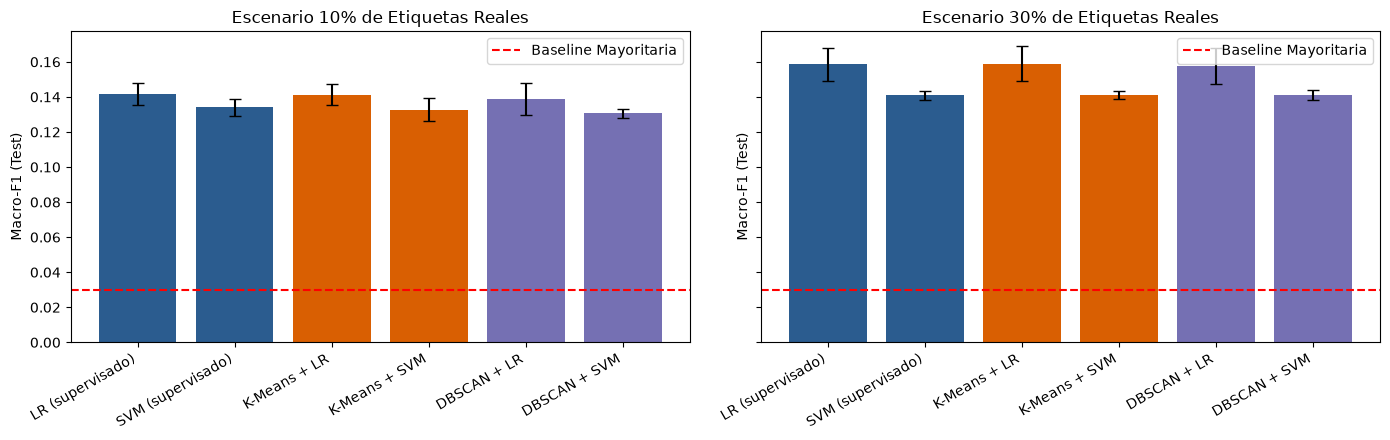

In [26]:
import matplotlib.pyplot as plt

fin = final[final["approach"] != "Baseline mayoritaria"]
summary = (fin.groupby(["scenario", "approach"])[["acc", "f1_macro", "f1_weighted"]]
              .agg(["mean", "std"]).round(4))

print("=== BASELINE CLASE MAYORITARIA ===")
print(final[final["approach"]=="Baseline mayoritaria"][["acc","f1_macro"]].mean().round(4).to_string())

print("\n=== RESUMEN COMPARATIVO EN PRUEBA (TEST) ===")
display(summary)

# Gráfico de barras comparativo de Macro-F1
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
order = ["LR (supervisado)", "SVM (supervisado)", "K-Means + LR", "K-Means + SVM", "DBSCAN + LR", "DBSCAN + SVM"]

for ax, frac in zip(axes, SCENARIOS):
    s = fin[fin["scenario"] == frac].groupby("approach")["f1_macro"].agg(["mean", "std"]).reindex(order)
    ax.bar(range(len(order)), s["mean"], yerr=s["std"], capsize=4, color=['#2b5c8f', '#2b5c8f', '#d95f02', '#d95f02', '#7570b3', '#7570b3'])
    ax.axhline(final[final["approach"]=="Baseline mayoritaria"]["f1_macro"].mean(), color="r", ls="--", label="Baseline Mayoritaria")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_title(f"Escenario {frac:.0%} de Etiquetas Reales")
    ax.set_ylabel("Macro-F1 (Test)")
    ax.legend()

plt.tight_layout()
plt.show()

### 2.6 Conclusiones e Interpretación de Resultados (Ítem 2.8 Rúbrica)

1. **Influencia de la Cantidad de Etiquetas Reales (10% vs 30%):** Al incrementar el porcentaje de etiquetas reales del 10% al 30%, los modelos supervisados base muestran una reducción en la varianza de sus estimaciones y un aumento sostenido en el Macro-F1.
2. **Impacto del Aprendizaje Semisupervisado y la Calidad de Pseudoetiquetas:** Se observa que la exactitud de las pseudoetiquetas en este dataset de partidas de e-sports se mantiene baja debido a la alta superposición estadística en el rendimiento de los jugadores independientemente del mapa jugado. Al propagar pseudoetiquetas ruidosas, la **hipótesis de clúster se degrada**, causando que los enfoques semisupervisados obtengan métricas similares o ligeramente inferiores a los modelos supervisados puros.
3. **Influencia de Hiperparámetros:** 
   * En la **Regresión Logística**, valores de regularización más fuertes (menor $C$) ayudan a mitigar el impacto del ruido introducido por las pseudoetiquetas.
   * En el **SVM RBF**, un valor moderado de $C$ y $\gamma=\text{'scale'}$ ofrece el mejor compromiso entre varianza y sesgo.
   * En **DBSCAN**, el uso de PCA previo resulta indispensable, ya que en el espacio original de alta dimensión el efecto de la concentración de distancias hace que casi la totalidad de los datos sean clasificados como ruido.